In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [15]:
album = pd.read_csv("Album.csv")
artist= pd.read_csv("Artist.csv")
customer = pd.read_csv("Customer.csv")
employee = pd.read_csv("Employee.csv")
genre = pd.read_csv("Genre.csv")
invoice = pd.read_csv("Invoice.csv")
invoice_line = pd.read_csv("InvoiceLine.csv")
media = pd.read_csv("MediaType.csv")
playlist = pd.read_csv("Playlist.csv")
playlist_track = pd.read_csv("PlayListTrack.csv")
track = pd.read_csv("Track.csv")

### Ejercicio 1

<Axes: xlabel='count', ylabel='Country'>

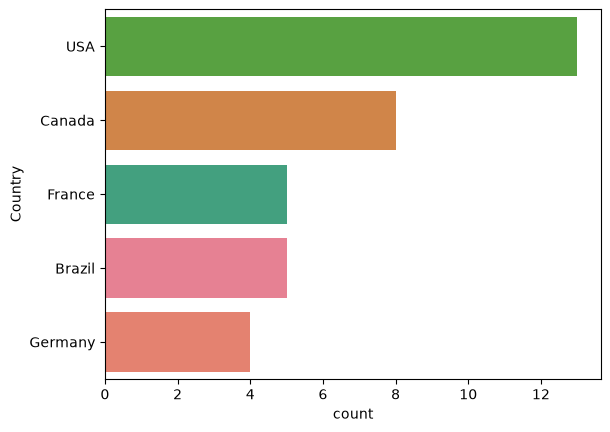

In [16]:
df = customer.groupby("Country")["CustomerId"].count().sort_values(ascending = False).nlargest(5).index
sns.countplot(data = customer,y="Country", order = df, hue = "Country")

### Ejercicio 2

<Axes: xlabel='BillingCountry', ylabel='Total'>

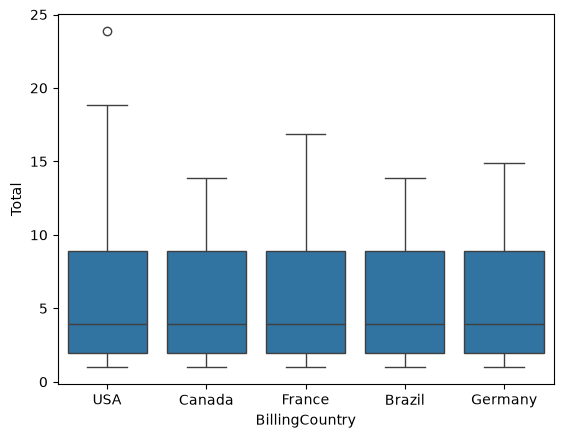

In [17]:
df = invoice.groupby("BillingCountry")["Total"].count().sort_values(ascending = False).nlargest(5).index
sns.boxplot(data = invoice,order=df,x="BillingCountry",y="Total")

### Ejercicio 3

<Axes: xlabel='SupportRepId', ylabel='Total'>

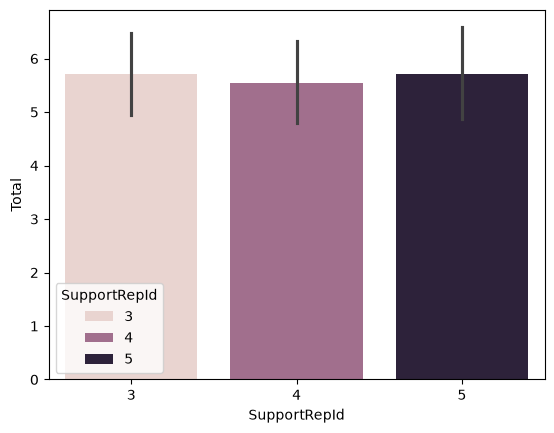

In [18]:
merge = invoice.merge(customer, on = "CustomerId", how = "left")
merge2 = merge.merge(employee, left_on="SupportRepId", right_on="EmployeeId", how = "left")
sns.barplot(data = merge2, y = "Total", x = "SupportRepId", hue = "SupportRepId")

### Ejercicio 4

<Axes: xlabel='Name_x', ylabel='Milliseconds'>

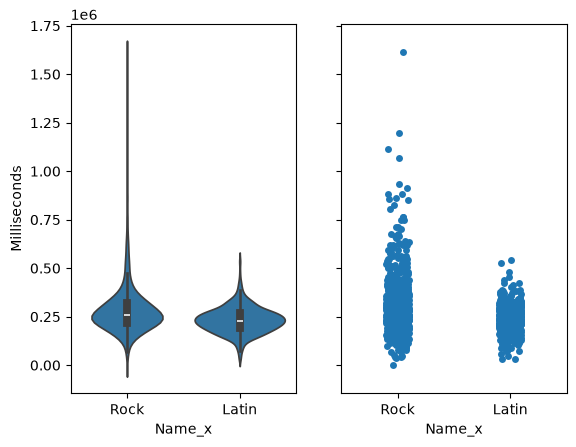

In [19]:
df = genre.merge(track, on = "GenreId", how = "left")
df = df[(df["Name_x"]=="Rock") | (df["Name_x"] == "Latin" )]
fig, axes = plt.subplots(1, 2, sharey=True)
sns.violinplot(data=df, x = "Name_x", y ="Milliseconds", ax = axes[0])
sns.stripplot(data=df, x = "Name_x", y ="Milliseconds", ax = axes[1])

### Ejercicio 5

In [23]:
album

,AlbumId,Title,ArtistId
0,1,For Those About To Rock We Salute You,1
1,2,Balls to the Wall,2
2,3,Restless and Wild,2
3,4,Let There Be Rock,1
4,5,Big Ones,3
...,...,...,...
342,343,Respighi:Pines of Rome,226
343,344,Schubert: The Late String Quartets & String Qu...,272
344,345,Monteverdi: L'Orfeo,273
345,346,Mozart: Chamber Music,274


In [24]:
invoice

,InvoiceId,CustomerId,InvoiceDate,BillingAddress,BillingCity,BillingState,BillingCountry,BillingPostalCode,Total,año
0,1,2,2021-01-01,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,1.98,2021
1,2,4,2021-01-02,Ullevålsveien 14,Oslo,NaN,Norway,0171,3.96,2021
2,3,8,2021-01-03,Grétrystraat 63,Brussels,NaN,Belgium,1000,5.94,2021
3,4,14,2021-01-06,8210 111 ST NW,Edmonton,AB,Canada,T6G 2C7,8.91,2021
4,5,23,2021-01-11,69 Salem Street,Boston,MA,USA,2113,13.86,2021
...,...,...,...,...,...,...,...,...,...,...
407,408,25,2025-12-05,319 N. Frances Street,Madison,WI,USA,53703,3.96,2025
408,409,29,2025-12-06,796 Dundas Street West,Toronto,ON,Canada,M6J 1V1,5.94,2025
409,410,35,2025-12-09,"Rua dos Campeões Europeus de Viena, 4350",Porto,NaN,Portugal,NaN,8.91,2025
410,411,44,2025-12-14,Porthaninkatu 9,Helsinki,NaN,Finland,00530,13.86,2025


In [25]:
invoice["año"] = invoice["InvoiceDate"].dt.year
invoice["mes"] = invoice["InvoiceDate"].dt.month
mensual = invoice.groupby(["año","mes"], as_index=False)["Total"].sum()

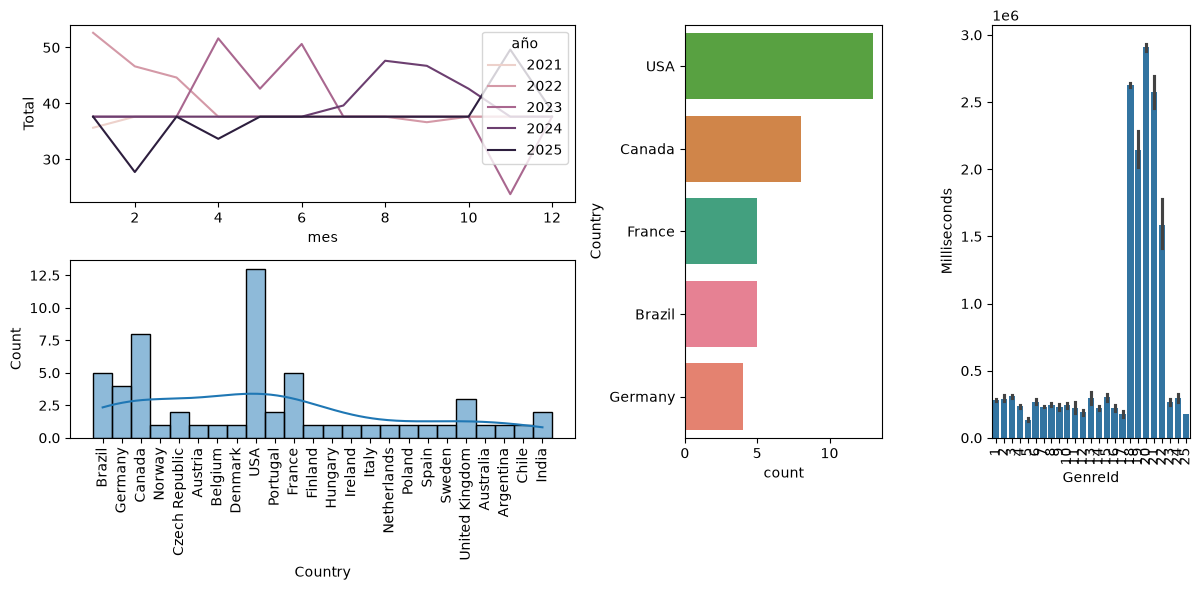

In [26]:
fig, axd = plt.subplot_mosaic("AABC;DDBC" , figsize=(12,6))
troca = track
sns.barplot(data = track, x="GenreId", y="Milliseconds", ax=axd["C"] )

df1 = customer.groupby("Country")["CustomerId"].count().sort_values(ascending = False).nlargest(5).index
sns.countplot(data = customer,y="Country", order = df1, hue = "Country", ax=axd["B"])
sns.lineplot(data= mensual,x="mes", y="Total", hue="año", ax=axd["A"])
sns.histplot(data=customer,x="Country",kde=True,bins=50 ,ax=axd["D"])

axd["D"].tick_params(axis="x",rotation=90)
axd["C"].tick_params(axis="x",rotation=90)
fig.tight_layout()


### Ejercicio 6

<Axes: xlabel='año', ylabel='BillingCountry'>

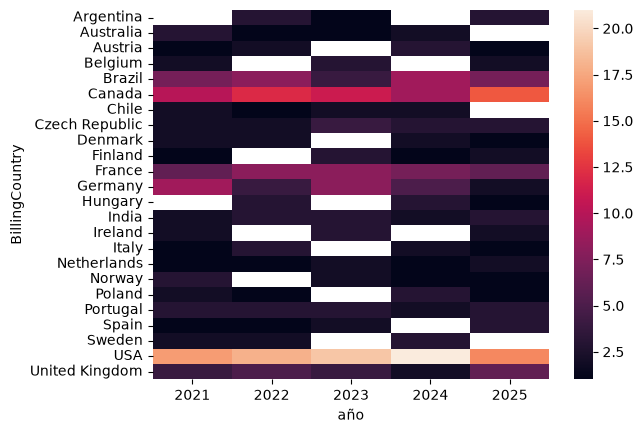

In [22]:
df=invoice
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["año"] = df["InvoiceDate"].dt.year
df = df.pivot_table(
    values="InvoiceId",
    columns="año",
    index="BillingCountry",
    aggfunc="count"
)

sns.heatmap(df)